# Image processing and face-authorisation pipeline

This notebook builds the image features and face model, evaluates it, and tests authorized and unauthorized examples.

In [7]:
from pathlib import Path
import sys


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from image_pipeline import build_image_features_csv, train_face_model, verify_face

## Inspect the image data

Images in `data/images/` are used for training. Filenames determine labels.

In [8]:
images = sorted((ROOT / "data" / "images").iterdir())
[(image.name, image.stat().st_size) for image in images if image.is_file()]

[('flavia.jpeg', 491180),
 ('flavia1.jpeg', 523842),
 ('flavia3.jpeg', 515966),
 ('placide.HEIC', 833778),
 ('placide2.HEIC', 1147337),
 ('placide3.HEIC', 1199985),
 ('Shakira.jpeg', 94154),
 ('shakira2.jpeg', 83781),
 ('shakira3.jpeg', 88594),
 ('unauthorised_smile.png', 661317),
 ('unauthorised_surprised.png', 705502),
 ('unauthorized.jpeg', 81654)]

## Build features and train the model

In [9]:
features_path = build_image_features_csv(
    images_dir=ROOT / "data" / "images",
    output_path=ROOT / "data" / "image_features.csv",
)
metrics = train_face_model(
    features_path=features_path,
    model_path=ROOT / "models" / "face_model.pkl",
    metrics_path=ROOT / "models" / "face_metrics.json",
)
metrics

{'accuracy': 1.0, 'f1_weighted': 1.0, 'log_loss': 0.20260376998286553}

In [10]:
import pandas as pd

features = pd.read_csv(features_path)
features.groupby("label").size().sort_index()

label
Shakira         12
flavia          12
placide         12
unauthorised     8
unauthorized     4
dtype: int64

## Test an authorized example

In [11]:
verify_face(
    ROOT / "data" / "images" / "flavia.jpeg",
    model_path=ROOT / "models" / "face_model.pkl",
)

{'recognized': True, 'userId': 'flavia', 'confidence': 0.93}

## Test unauthorized examples

These images are included as the `unauthorized` class. The application still denies access because that class has no customer profile.

In [12]:
unauthorized_paths = [
    ROOT / "data" / "images" / "unauthorized.jpeg",
    ROOT / "data" / "images" / "unauthorised_smile.png",
    ROOT / "data" / "images" / "unauthorised_surprised.png",
]

{
    path.name: verify_face(path, model_path=ROOT / "models" / "face_model.pkl")
    for path in unauthorized_paths
}

{'unauthorized.jpeg': {'recognized': True,
  'userId': 'unauthorized',
  'confidence': 0.96},
 'unauthorised_smile.png': {'recognized': True,
  'userId': 'unauthorised',
  'confidence': 0.995},
 'unauthorised_surprised.png': {'recognized': True,
  'userId': 'unauthorised',
  'confidence': 0.96}}

## Image EDA and augmentation evidence

This section documents image quantity, expression coverage, dimensions, brightness, and augmentation effects.

,member,expression,filename,width,height,mean_brightness
0,Flavia,neutral,flavia3.jpeg,1242,2208,147.045435
1,Flavia,smile,flavia1.jpeg,1242,2208,152.840699
2,Flavia,surprised,flavia.jpeg,1242,2208,139.125574
3,Placide,neutral,placide2.HEIC,3024,4032,195.476836
4,Placide,smile,placide3.HEIC,3024,4032,190.365550
5,Placide,surprised,placide.HEIC,3024,4032,178.573915
6,Shakira,neutral,shakira3.jpeg,960,1280,124.069192
7,Shakira,smile,shakira2.jpeg,960,1280,128.594797
8,Shakira,surprised,Shakira.jpeg,960,1280,120.984247


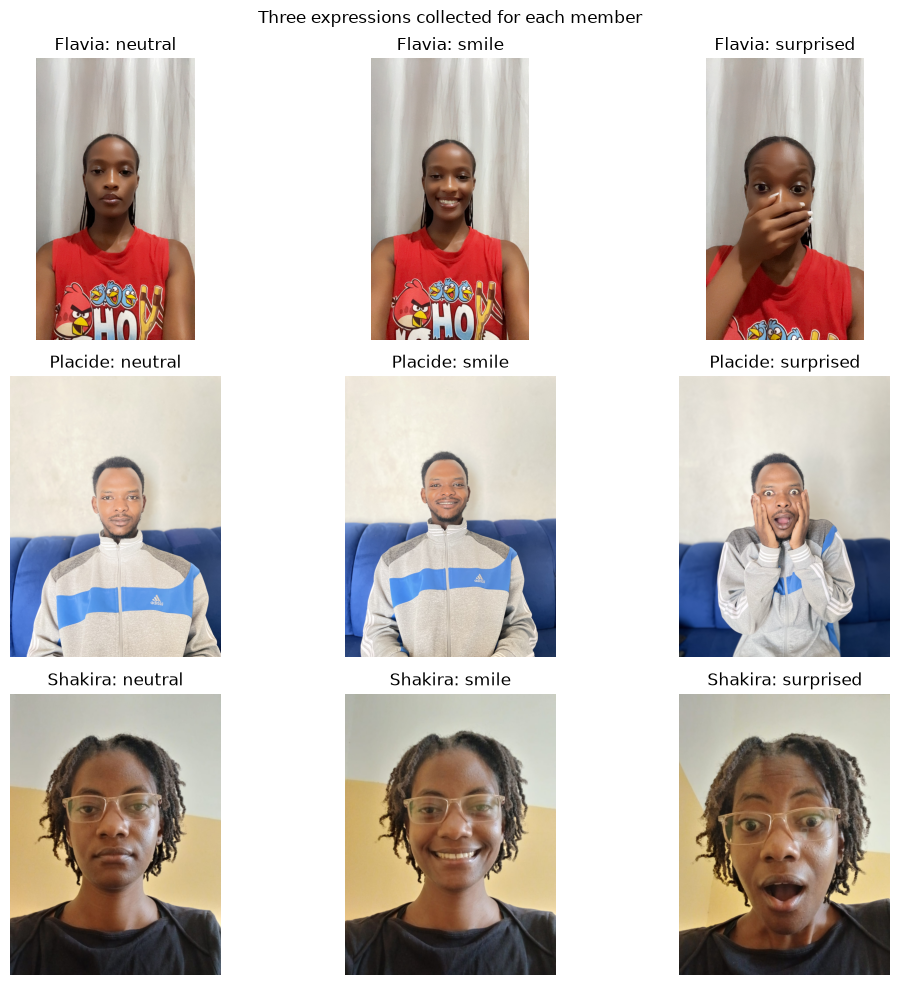

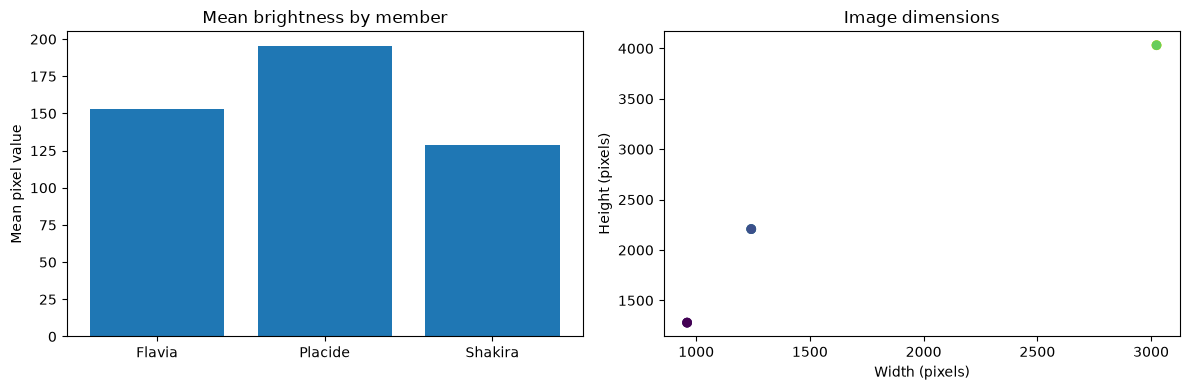

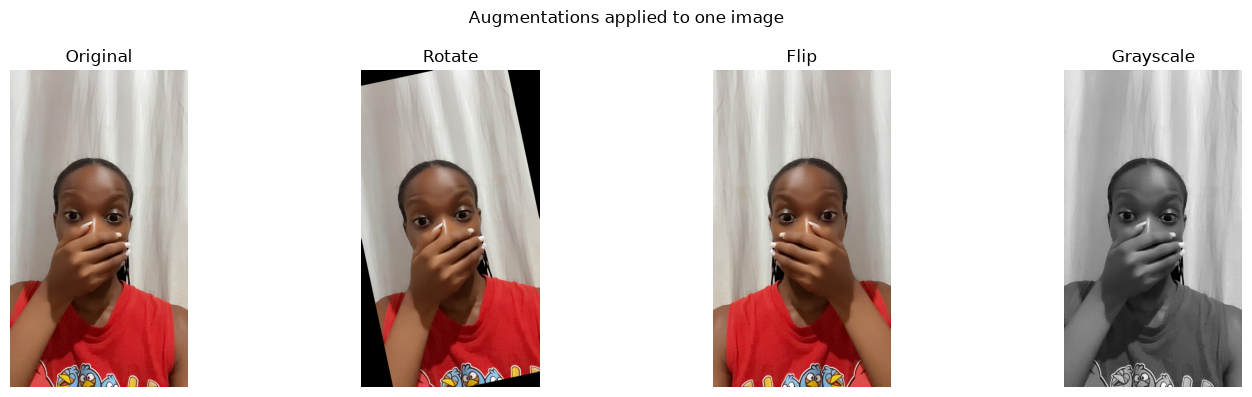

C:\Users\USER\AppData\Local\Temp\ipykernel_9112\933642506.py:63: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_frame["augmentation"] = feature_frame["source"].str.split(":").str[-1].where(feature_frame["source"].str.contains(":"), "original")


,rows
augmentation,
original,12
rotate,12
flip,12
grayscale,12


Interpretation: every member has three expression examples, and every original image has rotate, flip, and grayscale feature rows.
Resizing and normalization make feature lengths consistent despite differences in source dimensions and brightness.


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
features_path = ROOT / "data" / "image_features.csv"
register_heif_opener()

member_files = {
    "Flavia": ["flavia3.jpeg","flavia1.jpeg", "flavia.jpeg",  ],
    "Placide": ["placide2.HEIC", "placide3.HEIC","placide.HEIC"],
    "Shakira": ["shakira3.jpeg","shakira2.jpeg", "Shakira.jpeg" ],
}
expressions = ["neutral", "smile", "surprised"]
records = []
for member, filenames in member_files.items():
    for expression, filename in zip(expressions, filenames):
        with Image.open(ROOT / "data" / "images" / filename) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            records.append({
                "member": member, "expression": expression, "filename": filename,
                "width": rgb.width, "height": rgb.height,
                "mean_brightness": float(np.asarray(rgb).mean()),
            })
inventory = pd.DataFrame(records)
display(inventory)

fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for row, (member, filenames) in enumerate(member_files.items()):
    for column, (expression, filename) in enumerate(zip(expressions, filenames)):
        with Image.open(ROOT / "data" / "images" / filename) as image:
            axes[row, column].imshow(ImageOps.exif_transpose(image).convert("RGB"))
        axes[row, column].set_title(f"{member}: {expression}")
        axes[row, column].axis("off")
fig.suptitle("Three expressions collected for each member")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(inventory["member"], inventory["mean_brightness"])
axes[0].set(title="Mean brightness by member", ylabel="Mean pixel value")
axes[1].scatter(inventory["width"], inventory["height"], c=inventory["mean_brightness"])
axes[1].set(title="Image dimensions", xlabel="Width (pixels)", ylabel="Height (pixels)")
plt.tight_layout()
plt.show()

sample = ImageOps.exif_transpose(Image.open(ROOT / "data" / "images" / "flavia.jpeg")).convert("RGB")
augmented = [("Original", sample), ("Rotate", sample.rotate(12)), ("Flip", ImageOps.mirror(sample)), ("Grayscale", ImageOps.grayscale(sample))]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for axis, (title, image) in zip(axes, augmented):
    axis.imshow(image, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
fig.suptitle("Augmentations applied to one image")
plt.tight_layout()
plt.show()

feature_frame = pd.read_csv(features_path)
feature_frame["augmentation"] = feature_frame["source"].str.split(":").str[-1].where(feature_frame["source"].str.contains(":"), "original")
display(feature_frame["augmentation"].value_counts().rename_axis("augmentation").to_frame("rows"))
print("Interpretation: every member has three expression examples, and every original image has rotate, flip, and grayscale feature rows.")
print("Resizing and normalization make feature lengths consistent despite differences in source dimensions and brightness.")